# Final model (Run M): parameters, accuracy and predictions

This notebook loads the model we submitted and shows, with saved outputs:

1. its architecture and number of trainable parameters;
2. the held-out accuracy of its 45k twin on the 5,000 held-out training images;
3. its predictions on the 2,000 hidden images, recomputed from the weights and compared with the submitted CSV;
4. the final test accuracy from Kaggle;
5. the training curves.

Nothing is trained here, so it runs on a CPU, an Apple GPU or CUDA in a few minutes. It needs the competition data in
`data/` (see the README). Training commands for Run M and its teachers are in
`submissions/Abhinav_Run-M/README.md`.

In [1]:
import json
import os

if os.path.basename(os.getcwd()) == "notebooks":  # run from the repository root
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.data import CLASSES, build_test_loader, build_val_loader
from src.models import PARAM_BUDGET, count_params
from src.predict import balance_probs, predict_probs
from src.train import get_device, load_model, tta_probs

RUN = "submissions/Abhinav_Run-M"
DATA = "data"
device = get_device()
print("device:", device)

device: mps


## 1. Architecture and parameter count

`resnet_c` (`src/models.py`) is a post-activation ResNet: a 3×3 stem, three stages of BasicBlocks (two 3×3
convolutions with batch normalization and a skip connection), global average pooling and one linear layer. A 1×1
projection shortcut is used only where the number of channels changes.

In [2]:
model = load_model(f"{RUN}/model.pt", device)
config = json.load(open(f"{RUN}/config.json"))
print("architecture:", config["model"])

def n(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

rows = [("stem", "3x3 conv, 64 channels", "32x32", f"{n(model.stem):,}")]
stages = {}
for block in model.layers:
    stages.setdefault(block.conv2.out_channels, []).append(block)
for i, (channels, blocks) in enumerate(stages.items(), 1):
    size = 32 // 2 ** (i - 1)
    rows.append((f"stage {i}", f"{len(blocks)} BasicBlocks, {channels} channels", f"{size}x{size}",
                 f"{sum(n(b) for b in blocks):,}"))
rows.append(("fc", "global average pool + linear 256 -> 10", "1x1", f"{n(model.fc):,}"))
print(pd.DataFrame(rows, columns=["part", "layout", "feature map", "parameters"]).to_string(index=False))

n_params = count_params(model)
assert n_params <= PARAM_BUDGET
print(f"\nTrainable parameters: {n_params:,} (budget {PARAM_BUDGET:,})")

architecture: resnet_c
   part                                 layout feature map parameters
   stem                  3x3 conv, 64 channels       32x32      1,856
stage 1             3 BasicBlocks, 64 channels       32x32    221,952
stage 2            4 BasicBlocks, 128 channels       16x16  1,116,416
stage 3            3 BasicBlocks, 256 channels         8x8  3,280,384
     fc global average pool + linear 256 -> 10         1x1      2,570

Trainable parameters: 4,623,178 (budget 5,000,000)


## 2. Held-out accuracy

The submitted model was trained on all 50,000 training images, so it has no held-out set. Its twin, trained with the
same recipe on 45,000 images, is evaluated on the other 5,000 (500 per class, split seed 0). These are the held-out
numbers in the report. The decoding used for the submission is flip-and-shift TTA (10 views) plus class-balanced
decoding.

In [3]:
twin = load_model(f"{RUN}/twin/model.pt", device)
val_loader = build_val_loader(DATA, val_size=5000, seed=0)
y_val = np.concatenate([y.numpy() for _, y in val_loader])

@torch.no_grad()
def val_probs(net, tta):
    return torch.cat([tta_probs(net, x.to(device), tta).cpu() for x, _ in val_loader]).numpy()

acc = {}
for tta in ["none", "flip", "flip_shift"]:
    p = val_probs(twin, tta)
    acc[tta] = 100 * (p.argmax(1) == y_val).mean()
pred_val = balance_probs(p).argmax(1)  # p is the flip_shift output
acc["flip_shift + balanced"] = 100 * (pred_val == y_val).mean()
for k, v in acc.items():
    print(f"held-out accuracy, {k:22s} {v:.2f}%")

held-out accuracy, none                   97.80%
held-out accuracy, flip                   97.94%
held-out accuracy, flip_shift             98.00%
held-out accuracy, flip_shift + balanced  97.96%


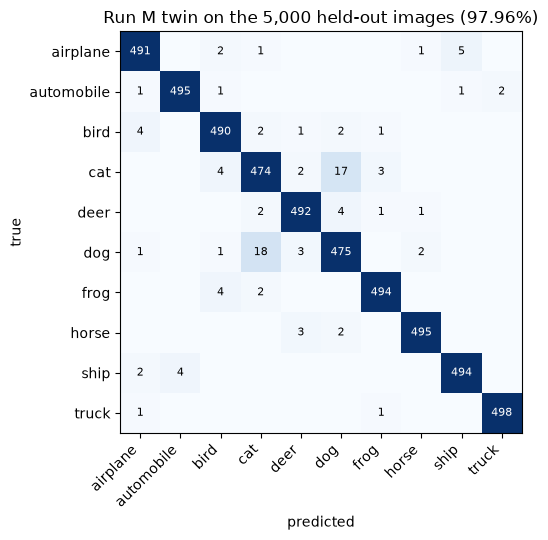

per-class accuracy: airplane 98.2, automobile 99.0, bird 98.0, cat 94.8, deer 98.4, dog 95.0, frog 98.8, horse 99.0, ship 98.8, truck 99.6


In [4]:
cm = np.zeros((10, 10), int)
np.add.at(cm, (y_val, pred_val), 1)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmax=0.2)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if i == j else "black")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Run M twin on the 5,000 held-out images ({acc['flip_shift + balanced']:.2f}%)")
plt.tight_layout()
plt.show()
print("per-class accuracy:", ", ".join(f"{c} {100 * cm[i, i] / cm[i].sum():.1f}" for i, c in enumerate(CLASSES)))

## 3. Predictions on the 2,000 hidden images

The final model predicts the hidden images with flip-and-shift TTA; class-balanced decoding then rescales the
predicted probabilities (Sinkhorn, temperature 1) so that each class gets the same total probability mass. It uses only
the unlabeled predictions and was approved by the professor. The result is compared with the CSV we submitted.

class-balanced decoding changed 70 of 2,000 predictions
recomputed predictions match the submitted CSV on 2,000 of 2,000 images


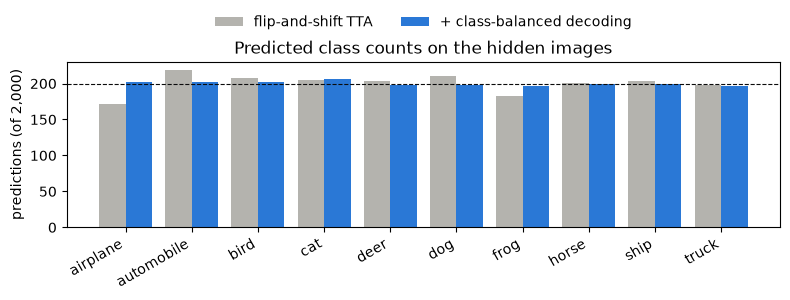

In [5]:
test_loader, ids = build_test_loader(DATA)
probs = predict_probs(model, test_loader, device, tta="flip_shift")
plain = probs.argmax(1)
balanced = balance_probs(probs).argmax(1)
print(f"class-balanced decoding changed {(plain != balanced).sum()} of {len(ids):,} predictions")

submitted = pd.read_csv(f"{RUN}/submission.csv")
assert (submitted.id.to_numpy() == ids).all()
same = (submitted.label.to_numpy() == balanced).sum()
print(f"recomputed predictions match the submitted CSV on {same:,} of {len(ids):,} images")

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(10)
ax.bar(x - 0.2, np.bincount(plain, minlength=10), 0.4, label="flip-and-shift TTA", color="#b4b3ae")
ax.bar(x + 0.2, np.bincount(balanced, minlength=10), 0.4, label="+ class-balanced decoding", color="#2a78d6")
ax.axhline(200, color="#0b0b0b", lw=0.8, ls="--")
ax.set_xticks(x, CLASSES, rotation=30, ha="right")
ax.set_ylabel("predictions (of 2,000)")
ax.set_title("Predicted class counts on the hidden images")
ax.legend(frameon=False, ncols=2, loc="lower center", bbox_to_anchor=(0.5, 1.12))
plt.tight_layout()
plt.show()

## 4. Final test accuracy

The hidden labels are not public, so the test accuracy is Kaggle's score for the submitted CSV: the public
leaderboard uses about 1,000 of the 2,000 hidden images and the private leaderboard the rest
(`report/data/team_submissions.csv`, downloaded from Kaggle after the competition closed).

In [6]:
subs = pd.read_csv("report/data/team_submissions.csv")
m = subs[subs.description.str.startswith("Run M:")].iloc[0]
print(f"Run M, {config['model']}, {n_params:,} trainable parameters")
print(f"held-out accuracy (45k twin, flip-and-shift + balanced): {acc['flip_shift + balanced']:.2f}%")
print(f"final test accuracy: public {100 * m.publicScore:.1f}%, private {100 * m.privateScore:.1f}% "
      f"(6th of 81 teams on the private leaderboard)")

Run M, resnet_c, 4,623,178 trainable parameters
held-out accuracy (45k twin, flip-and-shift + balanced): 97.96%
final test accuracy: public 91.0%, private 89.3% (6th of 81 teams on the private leaderboard)


## 5. Training curves

600 epochs, about 20 s each on one A100. Training accuracy is measured on the augmented batches (MixUp/CutMix on half
of them, hard-factor augmentation on 30% of the images), so it stays far below the held-out accuracy.

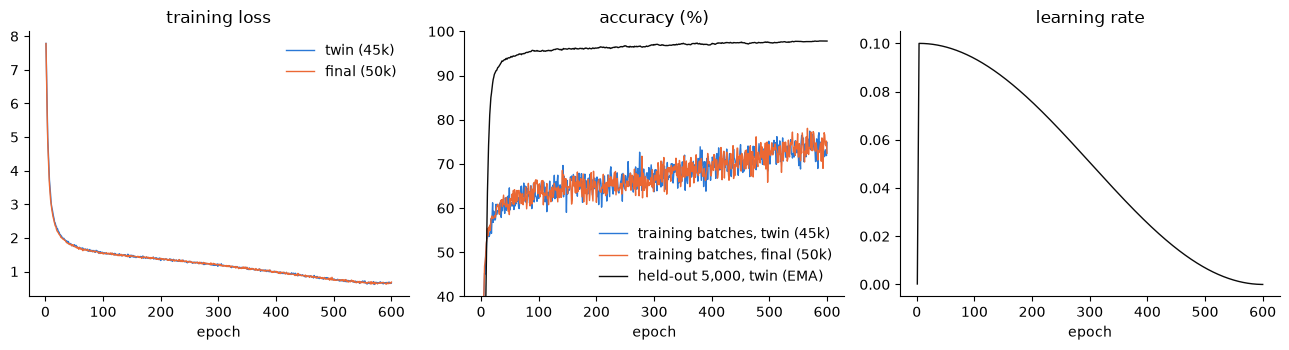

twin held-out accuracy at epoch 600 (EMA, no TTA): 97.80%


In [7]:
hist = {name: pd.DataFrame(json.load(open(path)))
        for name, path in [("twin (45k)", f"{RUN}/twin/history.json"), ("final (50k)", f"{RUN}/history.json")]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for (name, h), color in zip(hist.items(), ["#2a78d6", "#eb6834"]):
    axes[0].plot(h.epoch, h.train_loss, color=color, lw=1, label=name)
    axes[1].plot(h.epoch, h.train_acc, color=color, lw=1, label=f"training batches, {name}")
h = hist["twin (45k)"]
axes[1].plot(h.epoch, h.val_acc, color="#0b0b0b", lw=1, label="held-out 5,000, twin (EMA)")
axes[2].plot(h.epoch, h.lr, color="#0b0b0b", lw=1)
axes[0].set(title="training loss", xlabel="epoch")
axes[1].set(title="accuracy (%)", xlabel="epoch", ylim=(40, 100))
axes[2].set(title="learning rate", xlabel="epoch")
axes[0].legend(frameon=False)
axes[1].legend(frameon=False, loc="lower right")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"twin held-out accuracy at epoch {h.epoch.iloc[-1]} (EMA, no TTA): {h.val_acc.iloc[-1]:.2f}%")